> **Historical first run, retained unchanged below.** The current v1-only reproduction is organized in the four [canonical notebooks](notebooks/01_design_and_data_audit.ipynb). See [README.md](README.md) for the sequence and [WEBSITE_HANDOFF.md](WEBSITE_HANDOFF.md) for the page preparation. Use the canonical notebooks for future changes.

# Can showing popularity change a music market?
## Music Lab v1: inequality first, unpredictability second

A learning reproduction of Salganik, Dodds & Watts (2006), *Experimental Study of Inequality and Unpredictability in an Artificial Cultural Market*, **Science 311:854–856**, [DOI](https://doi.org/10.1126/science.1121066).

[Paper and supporting material](https://www.princeton.edu/~mjs3/salganik_dodds_watts06_full.pdf) · [Standalone supplement](https://pdodds.w3.uvm.edu/research/papers/years/2006/salganik2006a_supp.pdf), especially printed pp. 9–11.

**Scope:** original experiment v1 only. Eight social worlds show prior downloads; independent world 9 hides them. Both conditions randomly place the same 48 songs on a grid. Participants were randomly assigned, with 20% allocated to the independent group and 10% to each social world.

We reproduce the reported metrics and random-halving procedure using the released participant records. Our seed and odd-sample split convention are explicit; this is not an exact recreation of the authors' random draws. Raw files remain untouched. The release already excludes potentially contaminated activity.

**Before running:** Would you expect displaying popularity to change which songs win, how unequal downloads become, or both?

In [1]:
from pathlib import Path
from itertools import combinations
import hashlib, io, json, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 20261125
N_SPLITS = 1000
# Run from this folder, its notebooks folder, or the statistical-experiments root.
here = Path.cwd()
candidates = [here, here.parent] + list(here.glob('experiment2*'))
ROOT = next(p for p in candidates if (p / 'musiclab_data.zip').exists())
OUT = ROOT / 'outputs' / 'v1-reproduction'
OUT.mkdir(parents=True, exist_ok=True)
ARCHIVE = ROOT / 'musiclab_data.zip'
plt.rcParams.update({'figure.dpi': 130, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold'})

def read_table(name):
    with zipfile.ZipFile(ARCHIVE) as z:
        return pd.read_csv(io.BytesIO(z.read(name)), header=None, comment='%', skipinitialspace=True)


### 1. Check what a row means
Each download-matrix row is a participant; the last 48 columns indicate whether they downloaded each song. Keep people with **zero downloads**: selecting only downloaders would change the randomly assigned population.

Song columns follow lexicographic song-ID order. We check IDs against the demographic records, binary values, and every published song-by-world total before analyzing anything.

In [2]:
totals = read_table('downloads_v1_lexorder.txt')
song_ids = totals.iloc[:, 0].astype(str).to_numpy()
demographics = read_table('user_demographics_v1.txt')
matrices = {}
world_rows = []
assert totals.shape == (48, 10)
assert list(song_ids) == sorted(song_ids)
for world in range(1, 10):
    frame = read_table(f'dynamics_downloads_w{world}_v1.txt')
    assert frame.shape[1] == 50
    assert frame.iloc[:, 0].is_unique
    assert (frame.iloc[:, 1] == world).all()
    expected_users = set(demographics.loc[demographics[1] == world, 0])
    assert set(frame.iloc[:, 0]) == expected_users
    x = frame.iloc[:, 2:].to_numpy(dtype=int)
    assert np.isin(x, [0, 1]).all()
    np.testing.assert_array_equal(x.sum(axis=0), totals.iloc[:, world].to_numpy())
    matrices[world] = x
    world_rows.append({'world': world, 'condition': 'independent' if world == 9 else 'social',
                       'participants': len(x), 'downloads': int(x.sum()),
                       'zero_download_participants': int((x.sum(axis=1) == 0).sum())})
world_summary = pd.DataFrame(world_rows)
assert world_summary.participants.sum() == 7149
assert world_summary.downloads.sum() == 8203
print('All 48 song totals agree in all 9 worlds; every participant is retained.')
display(world_summary)


All 48 song totals agree in all 9 worlds; every participant is retained.


,world,condition,participants,downloads,zero_download_participants
0,1,social,702,657,490
1,2,social,699,834,485
2,3,social,716,732,499
3,4,social,719,871,514
4,5,social,709,755,476
5,6,social,705,944,494
6,7,social,715,1013,496
7,8,social,743,819,512
8,9,independent,1441,1578,1038


### 2. Measure success and inequality
**Market share** = song downloads / all downloads in that world. This describes where downloads go, not download probability per participant.

The **Gini coefficient** averages absolute differences between song shares, with normalization:

$$G = \frac{\sum_i\sum_j |m_i-m_j|}{2S\sum_i m_i},\quad S=48.$$

Equal shares give 0. With 48 songs this uncorrected formula has maximum 47/48 when one song gets everything. Higher means more concentrated success. We use the paper's formula without a finite-sample correction.

The full independent group is larger than each social world. Smaller samples can look more unequal just from sampling variation, so the paper compares social worlds with random **halves** of the independent participants.

In [3]:
def shares(counts):
    counts = np.asarray(counts, dtype=float)
    assert counts.sum() > 0
    return counts / counts.sum()

def gini(values):
    values = np.asarray(values, dtype=float)
    assert np.all(values >= 0) and values.sum() > 0
    return np.abs(values[:, None] - values[None, :]).sum() / (2 * len(values) * values.sum())

assert np.isclose(gini(np.ones(48)), 0)
assert np.isclose(gini(np.r_[1, np.zeros(47)]), 47 / 48)
social_shares = np.array([shares(matrices[w].sum(axis=0)) for w in range(1, 9)])
social_gini = np.array([gini(m) for m in social_shares])
world_summary['gini'] = [gini(matrices[w].sum(axis=0)) for w in range(1, 10)]
control = matrices[9]
rng = np.random.default_rng(SEED)
control_gini = np.empty(N_SPLITS)
control_u = np.empty(N_SPLITS)
for b in range(N_SPLITS):
    order = rng.permutation(len(control))
    # 1,441 participants split into 720 and 721; use the 720-person half for Gini.
    a, c = np.array_split(order, [len(control) // 2])
    ma, mc = shares(control[a].sum(axis=0)), shares(control[c].sum(axis=0))
    control_gini[b] = gini(ma)
    control_u[b] = np.abs(ma - mc).mean()

print(f'Independent half: mean Gini {control_gini.mean():.4f}')
print(f'Social worlds: mean Gini {social_gini.mean():.4f}; range {social_gini.min():.4f}–{social_gini.max():.4f}')
print(f'Mean difference: {social_gini.mean() - control_gini.mean():.4f}')
display(world_summary[['world', 'condition', 'participants', 'gini']].round(4))


Independent half: mean Gini 0.2578
Social worlds: mean Gini 0.3402; range 0.2838–0.4175
Mean difference: 0.0824


,world,condition,participants,gini
0,1,social,702,0.3344
1,2,social,699,0.3739
2,3,social,716,0.4175
3,4,social,719,0.3334
4,5,social,709,0.3788
5,6,social,705,0.2838
6,7,social,715,0.3002
7,8,social,743,0.2999
8,9,independent,1441,0.2438


### 3. Do worlds differ more than ordinary sampling would suggest?
For each pair of social worlds, compute the **mean absolute difference** in a song's market share across all 48 songs:

$$U_{ab}=\frac{1}{48}\sum_i |m_{ia}-m_{ib}|.$$

Average this over the 28 pairs to obtain the social-condition unpredictability metric. For the independent baseline, compare the two halves in each random split. This is not forecast error, rank variance, or a claim that a particular song is impossible to predict.

**Important:** the 28 pairs share worlds; the 1,000 splits reuse people. Neither supplies that many independent experiments.

In [4]:
pairs = list(combinations(range(8), 2))
social_u = np.array([np.abs(social_shares[a] - social_shares[b]).mean() for a, b in pairs])
pair_summary = pd.DataFrame({'world_a': [a+1 for a,b in pairs],
                             'world_b': [b+1 for a,b in pairs], 'unpredictability': social_u})
print(f'Independent halves: average difference {control_u.mean()*100:.3f} percentage points per song')
print(f'Social-world pairs: average difference {social_u.mean()*100:.3f} percentage points per song')
print(f'Ratio: {social_u.mean()/control_u.mean():.2f}× the independent baseline')

# Reproduce the comparison described by the authors, not a conventional t-test.
# Uniformly choose one observed social statistic and one control-split statistic.
gini_overlap = float((social_gini[:, None] < control_gini[None, :]).mean())
u_overlap = float((social_u[:, None] < control_u[None, :]).mean())
print(f'Fraction social Gini < independent split Gini: {gini_overlap:.5f}')
print(f'Fraction social pair U < independent split U: {u_overlap:.5f}')
print('The supplement reports < .01 for both v1 comparisons.')


Independent halves: average difference 0.492 percentage points per song
Social-world pairs: average difference 0.821 percentage points per song
Ratio: 1.67× the independent baseline
Fraction social Gini < independent split Gini: 0.01075
Fraction social pair U < independent split U: 0.00407
The supplement reports < .01 for both v1 comparisons.


### 4. See the comparisons
The shaded distributions show the independent group's random-split baseline. Individual marks show observed social worlds (left) or social-world pairs (right). Vertical dashed lines show means.

These distributions are **not confidence intervals for the treatment effect**. The overlap fractions follow the paper's reported procedure; they are not the probability that the causal claim is false, and zero observed overlap would not establish zero uncertainty.

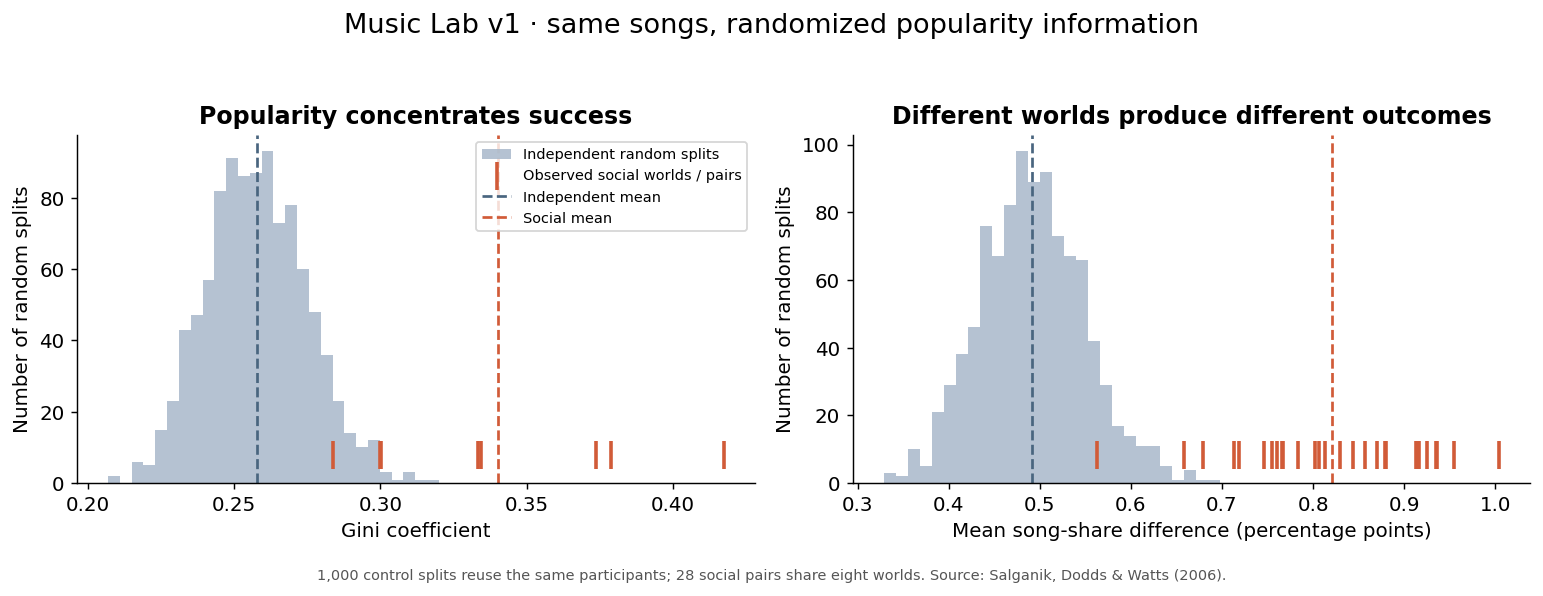

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, baseline, observed, xlabel, title in [
    (axes[0], control_gini, social_gini, 'Gini coefficient', 'Popularity concentrates success'),
    (axes[1], control_u*100, social_u*100, 'Mean song-share difference (percentage points)', 'Different worlds produce different outcomes')]:
    ax.hist(baseline, bins=28, color='#a8b8ca', alpha=.85, label='Independent random splits')
    top = ax.get_ylim()[1]
    ax.scatter(observed, np.full(len(observed), top*.08), color='#d15b38', marker='|', s=230,
               linewidths=2, label='Observed social worlds / pairs', zorder=5)
    ax.axvline(baseline.mean(), color='#49657f', linestyle='--', label='Independent mean')
    ax.axvline(observed.mean(), color='#d15b38', linestyle='--', label='Social mean')
    ax.set(xlabel=xlabel, ylabel='Number of random splits', title=title)
axes[0].legend(fontsize=8)
fig.suptitle('Music Lab v1 · same songs, randomized popularity information', fontsize=15)
fig.text(.5, .01, '1,000 control splits reuse the same participants; 28 social pairs share eight worlds. Source: Salganik, Dodds & Watts (2006).',
         ha='center', fontsize=8, color='#555555')
fig.tight_layout(rect=(0,.04,1,.94))
fig.savefig(OUT / 'v1_comparisons.png', dpi=180, bbox_inches='tight')
plt.show()


### 5. What the evidence supports—and what it does not

Random assignment supports a causal contrast between the two information environments. The same songs and randomized positions help isolate displaying download counts in **v1**. Greater inequality and greater world-to-world variation support the idea that social feedback can amplify early differences.

The independent worlds would differ even without feedback. That is why the random-split baseline matters. A dramatic rank change for one selected song is illustrative, but the comparisons above use **all 48 songs**.

Assumptions and limits:
- Participants should not import popularity information from other worlds. The release excludes some potentially contaminated activity, but we cannot fully audit exclusions from these released data.
- Within-world spillovers are the phenomenon being studied. Treating every download as an independent observation would ignore that structure.
- This is a market-level outcome, not proof that displaying counts changes intrinsic musical taste, or that talent does not matter.
- These participants, songs, free downloads and interface do not represent all contemporary music markets.
- We reproduce the authors' split-comparison procedure. A separate modern inference analysis would need to account for shared histories and the small number of worlds; we do not relabel the split distribution as a causal-effect confidence interval.

**Pause for discussion:** Why would comparing the eight worlds only with each other be insufficient evidence that popularity information increased unpredictability?

In [6]:
results = {
    'version': 1, 'seed': SEED, 'n_splits': N_SPLITS,
    'participants': int(world_summary.participants.sum()), 'songs': 48,
    'control_split_sizes': [len(control)//2, len(control)-len(control)//2],
    'independent_gini_mean': float(control_gini.mean()),
    'social_gini_mean': float(social_gini.mean()),
    'social_gini_range': [float(social_gini.min()), float(social_gini.max())],
    'gini_mean_difference': float(social_gini.mean()-control_gini.mean()),
    'independent_u_mean': float(control_u.mean()), 'social_u_mean': float(social_u.mean()),
    'u_ratio': float(social_u.mean()/control_u.mean()),
    'gini_comparison_fraction': gini_overlap, 'u_comparison_fraction': u_overlap,
    'comparison_definition': 'Fraction of all social-statistic/control-split pairs where social < control; authors comparison, not a conventional null-randomization p-value.',
    'data_sha256': hashlib.sha256(ARCHIVE.read_bytes()).hexdigest(),
    'source': 'https://doi.org/10.1126/science.1121066',
    'numpy_version': np.__version__, 'pandas_version': pd.__version__,
}
world_summary.to_csv(OUT / 'world_summary.csv', index=False)
pair_summary.to_csv(OUT / 'social_world_pairs.csv', index=False)
pd.DataFrame({'split': np.arange(1, N_SPLITS+1), 'gini': control_gini,
              'unpredictability': control_u}).to_csv(OUT / 'control_splits.csv', index=False)
(OUT / 'results.json').write_text(json.dumps(results, indent=2) + '\n')
print('Saved figure, results, world summaries, pair comparisons and all control splits to:', OUT)


Saved figure, results, world summaries, pair comparisons and all control splits to: /Users/aryamanwade/Documents/ChatGPT/Data Science Study/practice/statistical-experiments/experiment2-woulld song be a hit in 8 worlds/outputs/v1-reproduction


### 6. Replication check: a near-threshold discrepancy
Our initial 1,000-split run gives an inequality comparison fraction of **0.01075**, slightly above the paper's **< .01** statement. The unpredictability fraction is **0.00407**. We retain the initial results rather than searching for a seed that crosses the threshold.

To assess simulation sensitivity, perform one prespecified longer run: **10,000 splits, seed 20261126**. These remain repeated partitions of the same control sample. The standard error below measures only Monte Carlo precision of the comparison fraction, conditional on the observed data and eight worlds—not uncertainty in the causal effect. We also check the 721-person half for the Gini comparison because the control sample is odd.

Differences in original random draws, conventions, or release versions are possible explanations; none is established here.

In [7]:
sensitivity_rng = np.random.default_rng(20261126)
sensitivity_n = 10000
sensitivity_values = np.empty((sensitivity_n, 5))
for b in range(sensitivity_n):
    order = sensitivity_rng.permutation(len(control))
    a, c = np.array_split(order, [len(control)//2])
    ma, mc = shares(control[a].sum(axis=0)), shares(control[c].sum(axis=0))
    ga, gc, u = gini(ma), gini(mc), np.abs(ma-mc).mean()
    sensitivity_values[b] = [ga, gc, u, (social_gini < ga).mean(), (social_u < u).mean()]
sensitivity = {
    'seed': 20261126, 'n_splits': sensitivity_n,
    'gini_comparison_fraction_720': float(sensitivity_values[:,3].mean()),
    'gini_comparison_fraction_721': float((social_gini[:,None] < sensitivity_values[:,1]).mean()),
    'gini_comparison_monte_carlo_se': float(sensitivity_values[:,3].std(ddof=1)/np.sqrt(sensitivity_n)),
    'u_comparison_fraction': float(sensitivity_values[:,4].mean()),
    'u_comparison_monte_carlo_se': float(sensitivity_values[:,4].std(ddof=1)/np.sqrt(sensitivity_n)),
}
(OUT / 'sensitivity.json').write_text(json.dumps(sensitivity, indent=2) + '\n')
pd.DataFrame(sensitivity_values, columns=['gini_720','gini_721','u','gini_comparison','u_comparison']).to_csv(OUT/'sensitivity_splits.csv', index=False)
display(pd.Series(sensitivity))
print('Read these as conditional split comparisons; do not claim exact reproduction of the reported threshold.')

Read these as conditional split comparisons; do not claim exact reproduction of the reported threshold.


seed                              2.026113e+07
n_splits                          1.000000e+04
gini_comparison_fraction_720      1.222500e-02
gini_comparison_fraction_721      1.267500e-02
gini_comparison_monte_carlo_se    5.044357e-04
u_comparison_fraction             3.721429e-03
u_comparison_monte_carlo_se       1.150381e-04
dtype: float64

### Results to carry forward

- Mean Gini: **0.258** in independent halves versus **0.340** across social worlds; all eight social Ginis exceed the control-split mean.
- Mean between-world song-share difference: **0.492 percentage points** for independent halves versus **0.821 percentage points** for social pairs, approximately **1.67×**.
- Longer-run inequality comparison fraction: **0.012225** using 720-person halves (**0.012675** using 721-person halves). The original **< .01** inequality threshold is **not reproduced** by this implementation and released data. The substantive direction is reproduced; the source of the numerical discrepancy remains unresolved.
- Longer-run unpredictability comparison fraction: **0.003721**, consistent with the reported **< .01** comparison.

Our conclusion is about these observed markets and this explicitly documented resampling procedure. It does not turn these fractions into conventional causal-effect p-values. The next learning discussion can stay with Gini and the control-split baseline before moving to unpredictability.